# 숙제..

In [128]:
"""
* 주제 : 와인종류 분류하기
* 사용데이터 : 08_wine_exe.csv
  - 전처리 필요함
 
<분석방법>
 - 상관관계 분석..
 - 스케일링 : 모든 스케일러 각각 사용
 - 데이터분류 : 훈련:검증:테스트 = 6 : 2 : 2로 분류하여 사용
 - 튜닝 없이 전체 모델 훈련하여 ~ 평가까지..
 - 하이퍼파라메터 튜닝 후 전체 모델 훈련하여 ~ 평가까지..
 - 이외 훈련에 영햘을 미칠 수 있는, 모든 경우의 수 적용


<튜닝 클래스 사용 및 속성 : 제공된 값 이외에 각자 임의의 값 추가 적용하여 성능 테스트하기>
 * 랜덤포레스트, 엑스트라트리, 그레디언트부스트
  - n_estimators = [50, 100]
    : 트리 갯수 지정(보통 50~1000 사이값 사용)
  - max_depth = [None, 10]
    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)
  - min_samples_split = [2, 5]
    : 노드를 분할하기 위한 최소한의 샘플 수 (보통 2~10 사이값 사용)
  - min_samples_leaf = [1, 2, 4]
    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)
   
 * 히스트그레디언트부스트
  - max_iter = [50, 100]
    : 트리 갯수 지정(보통 50~1000 사이값 사용)
  - max_depth = [None, 10]
    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)
  - min_samples_leaf = [1, 2, 4]
    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)
   
 * 엑스지부스트
  - n_estimators = [50, 100]
    : 트리 갯수 지정(보통 50~1000 사이값 사용)
  - max_depth = [None, 10]
    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)
  - min_child_weight = [1, 2, 4]
    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)


<튜닝 자동화 모델(GridSearchCV 클래스)에서 사용할 튜닝 속성>
 * scoring = accuracy
    : 튜닝 자동화 모델(클래스)에 사용할 평가 방법 지정
    : 분류에서는 정확도를 이용
 
 * refit = accuracy
    : 튜닝 자동화 모델(클래스)에 사용할 모델 선정 기준 지정
    : scoring에서 한가지만 사용되기에 생략가능
 
 * cv = 5
    : 튜닝 자동화 모델(클래스)에 사용할 "교차검증" 시 사용할 Fold 갯수
    : Fold(폴드) -> 모델 훈련시 사용할 훈련데이터를 내부적으로
                 -> 폴드의 갯수만큼 다시 분류(훈련:검증으로)하여 사용하는 방법
                 
<최종 결과>
 * 각 처리 진행 시 해석 주석으로 작성
 
 * 데이터프레임에 아래 항목 저장하여 비교 후 모델 선정 (튜닝 전과 후로 각각 진행)
  - 모델명, 경우의수, 훈련정확도, 검증정확도, 테스트정확도,
    (훈련-검증)정확도, 정밀도, 재현율, F1-Score


 * 모델 선정 후, 테스트 데이터로 최종 예측 진행 (최종 선정 모델로 한번 진행)


<최종 제출>
 - 구글드랑브에 -> [개별 제출] 폴더 (홍길동.ipynb)
"""

'\n* 주제 : 와인종류 분류하기\n* 사용데이터 : 08_wine_exe.csv\n  - 전처리 필요함\n \n<분석방법>\n - 상관관계 분석..\n - 스케일링 : 모든 스케일러 각각 사용\n - 데이터분류 : 훈련:검증:테스트 = 6 : 2 : 2로 분류하여 사용\n - 튜닝 없이 전체 모델 훈련하여 ~ 평가까지..\n - 하이퍼파라메터 튜닝 후 전체 모델 훈련하여 ~ 평가까지..\n - 이외 훈련에 영햘을 미칠 수 있는, 모든 경우의 수 적용\n\n\n<튜닝 클래스 사용 및 속성 : 제공된 값 이외에 각자 임의의 값 추가 적용하여 성능 테스트하기>\n * 랜덤포레스트, 엑스트라트리, 그레디언트부스트\n  - n_estimators = [50, 100]\n    : 트리 갯수 지정(보통 50~1000 사이값 사용)\n  - max_depth = [None, 10]\n    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)\n  - min_samples_split = [2, 5]\n    : 노드를 분할하기 위한 최소한의 샘플 수 (보통 2~10 사이값 사용)\n  - min_samples_leaf = [1, 2, 4]\n    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)\n   \n * 히스트그레디언트부스트\n  - max_iter = [50, 100]\n    : 트리 갯수 지정(보통 50~1000 사이값 사용)\n  - max_depth = [None, 10]\n    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)\n  - min_samples_leaf = [1, 2, 4]\n    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)\n   \n * 엑스지부스트\n  - n_estimators = [50, 100]\n    : 트리 갯수 지정(보통 50~1000 사이값 사용)\n  - max_depth = [None, 10]

## 라이브러리 불러들이기

In [129]:
### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

### 상관관계 검정()
from scipy.stats import spearmanr, pearsonr

### 훈련/검증/테스트 데이터로 분리하는 함수
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


### 데이터 스케일링 표준화 클래스
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler

### 사용할 훈련모델 클래스
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier


from sklearn.model_selection import GridSearchCV

### 분류분석 오차 확인(평가) 라이브러리
# - 오차행렬표, 오차행렬도(그래프)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

### 분류모델 평가지표(선정기준)
# - 정확도, 정밀도, 재현율, f1-score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [130]:
# 파일 불러들이기
file_path = "./dataset/08_wine_exe.csv"
wine = pd.read_csv(file_path)
wine

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0
1,9.8,2.6,3.20,0
2,9.8,2.3,3.26,0
3,9.8,1.9,3.16,0
4,9.4,1.9,3.51,0
...,...,...,...,...
6492,11.2,1.6,3.27,1
6493,9.6,8.0,3.15,1
6494,9.4,1.2,2.99,1
6495,12.8,1.1,3.34,1


In [131]:
# wine 파일 정보 및 기본 수치 확인
wine.info()
wine.describe()
# sugar 및 pH에 결측치 확인.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6496 non-null   float64
 2   pH       6496 non-null   float64
 3   class    6497 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 203.2 KB


,alcohol,sugar,pH,class
count,6497.000000,6496.000000,6496.000000,6497.000000
mean,12.029357,5.443796,3.218458,0.753886
std,123.938942,4.757955,0.160762,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,10000.000000,65.800000,4.010000,1.000000


## 결측치 및 이상치 대체

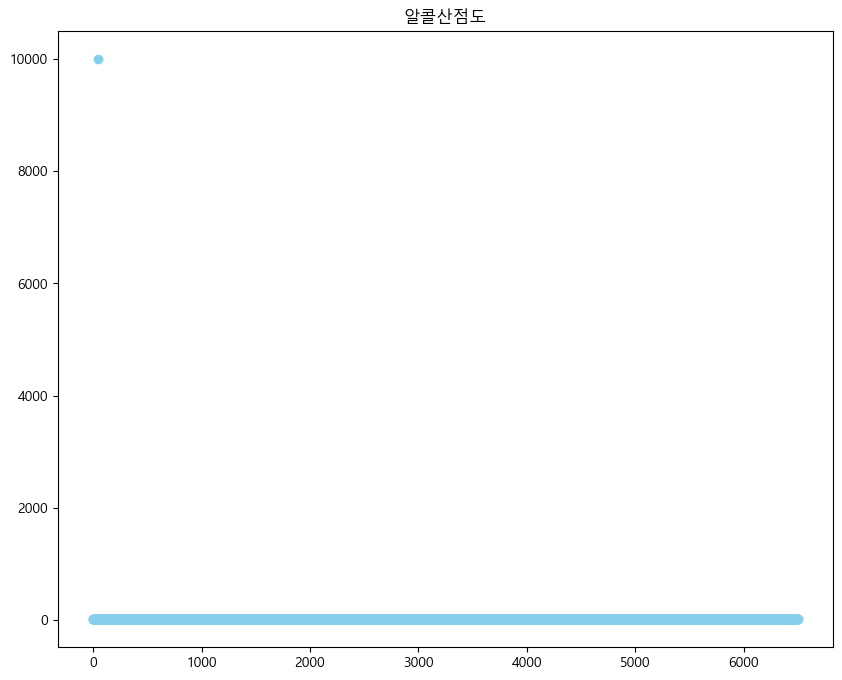

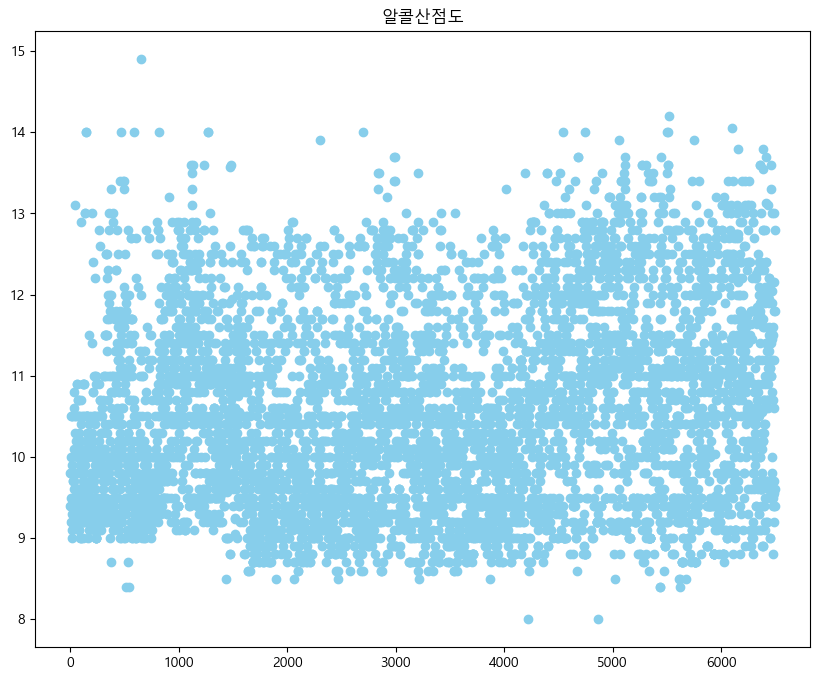

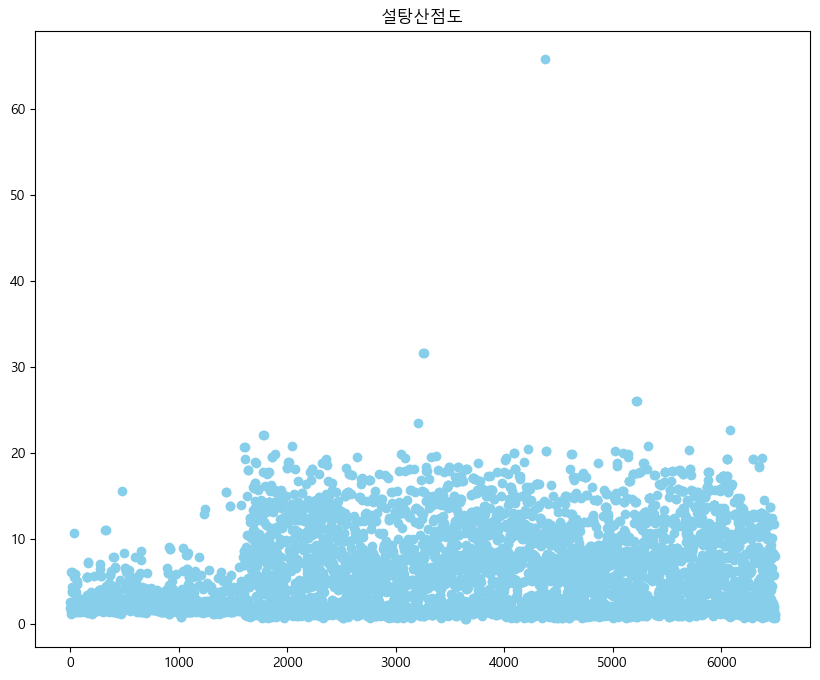

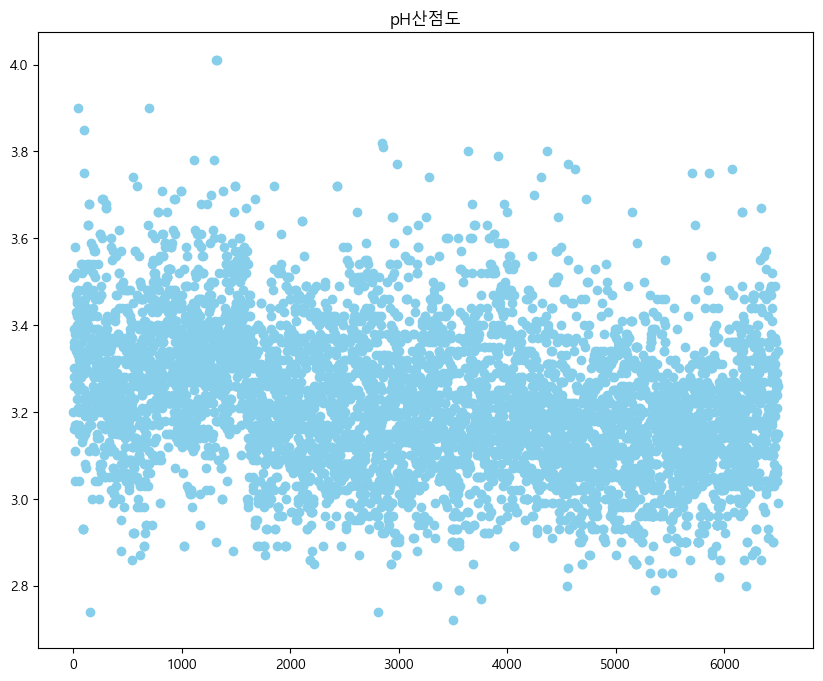

In [132]:
### 각 컬럼별 이상치를 산점도로 확인하기
# 알콜의 산점도
alcohol = wine["alcohol"]
plt.figure(figsize=(10,8))

plt.title("알콜산점도")

plt.scatter(alcohol.index, alcohol, c="skyblue", label="alcohol")

plt.show()
# 알콜 10,000인 데이터는 이상치라고 볼 수 있음. 산점도가 보기 너무 어려워, 10,000을 제외 후 확인해보기
wine_c=wine[wine["alcohol"] != 10000]

alcohol_c = wine_c["alcohol"]
plt.figure(figsize=(10,8))

plt.title("알콜산점도")

plt.scatter(alcohol_c.index, alcohol_c, c="skyblue", label="alcohol")

plt.show()


# 설탕의 산점도
sugar = wine["sugar"]
plt.figure(figsize=(10,8))

plt.title("설탕산점도")

plt.scatter(sugar.index, sugar, c="skyblue", label="sugar")

plt.show()
# pH의 산점도
ph = wine["pH"]
plt.figure(figsize=(10,8))

plt.title("pH산점도")

plt.scatter(ph.index, ph, c="skyblue", label="pH")

plt.show()

In [133]:
wine.loc[wine['alcohol'] == 10000, ['sugar', 'pH']].values

array([[2.6 , 3.21]])

![alt text](image.png)
- 분류 불가로 alcohol 10000 데이터는 빼는 것으로 결정

In [134]:
wine=wine[wine["alcohol"] != 10000]
wine.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6496 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6496 non-null   float64
 1   sugar    6495 non-null   float64
 2   pH       6495 non-null   float64
 3   class    6496 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 253.8 KB


In [135]:
print(wine.loc[wine['sugar'].isna(), ['alcohol', 'pH']].values)
print(wine.loc[wine['pH'].isna(), ['alcohol', 'sugar']].values)
## 분류 불가로 sugar 결측치 및 pH 결측치도 빼는 것으로 결정
wine = wine.dropna()
wine.info()

[[9.2  3.38]]
[[9.8 1.5]]
<class 'pandas.core.frame.DataFrame'>
Index: 6494 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6494 non-null   float64
 1   sugar    6494 non-null   float64
 2   pH       6494 non-null   float64
 3   class    6494 non-null   int64  
dtypes: float64(3), int64(1)
memory usage: 253.7 KB


,alcohol,sugar,pH,class
alcohol,1.000000,-0.359703,0.121625,0.032550
sugar,-0.359703,1.000000,-0.267100,0.348521
pH,0.121625,-0.267100,1.000000,-0.328736
class,0.032550,0.348521,-0.328736,1.000000


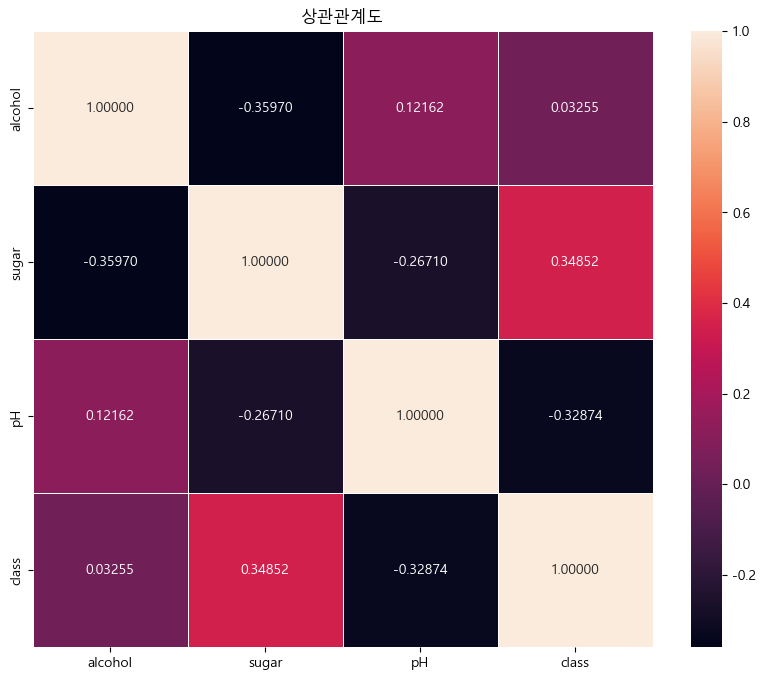

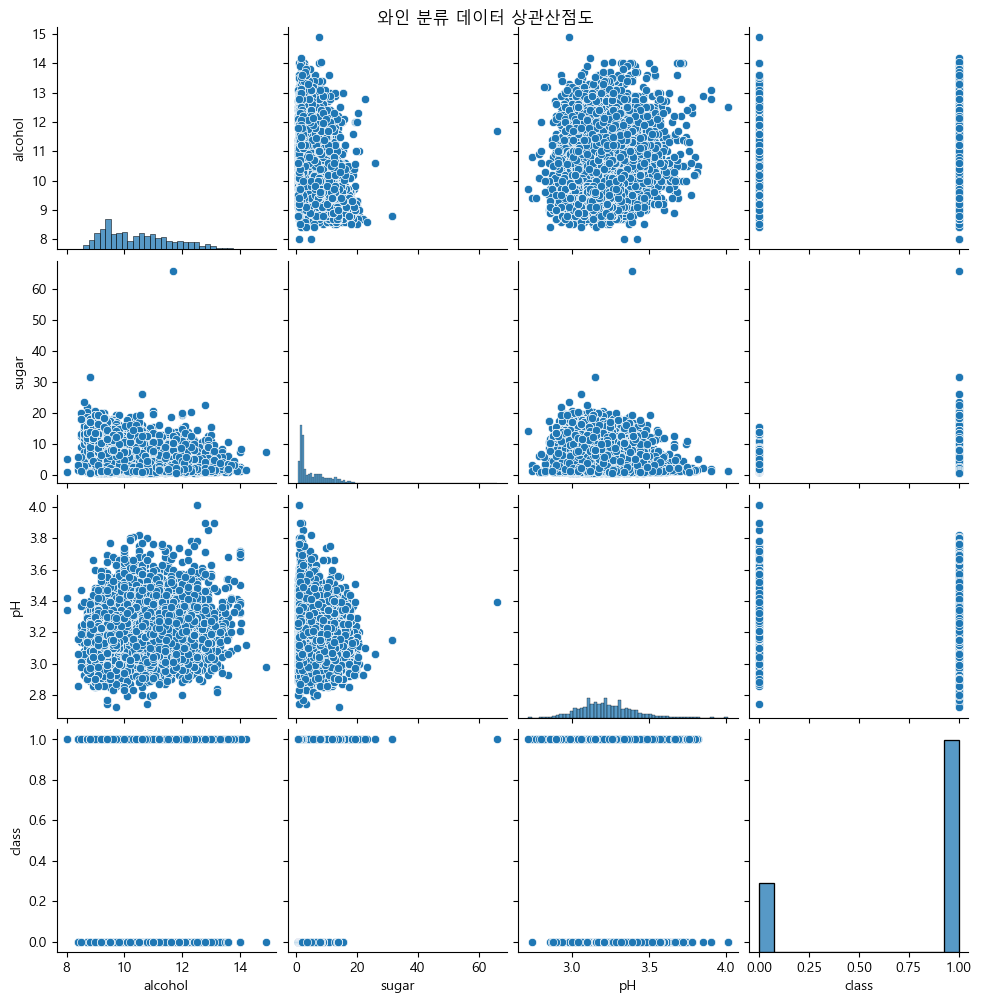

In [189]:
# 상관관계 검증하기
# spearmanr
# pearsonr
display(wine.corr())
wine_corr = wine.corr()
# 알콜과 클래스 상관관계 상당히 낮음.

# 상관관계도
plt.figure(figsize=(10,8))
plt.title("상관관계도")
sns.heatmap(wine_corr, annot=True, fmt=".5f", linewidths=0.5)
plt.show()

# 상관행렬도
sns.pairplot(wine)
plt.suptitle("와인 분류 데이터 상관산점도", y=1)
plt.show()

In [ ]:
# 독립변수 : X(알콜, 당류, pH)
# 종속변수 : y(클래스)
X = wine.iloc[:,:-1].to_numpy()
y = wine["class"].to_numpy()

print(X.shape, y.shape)

(6494, 3) (6494,)


In [ ]:
# 상관계수 및 유의미성 확인
s_p = [spearmanr, pearsonr]
cols = ["alcohol", "sugar", "pH"]

for c in s_p:
    c_nm = c.__name__ # 함수라 앞에 class 안 써도 됨.
    print(f"=========================================={c_nm}============================================")
    for col in cols:
        s, p = c(wine[col], y)
        if p < 0.05:
            print(f"""{col}과 class의 유의미성을 검증해보았을 때,
상관계수는"" {s:.5f}, 유의미계수는 {p:.5f},
유의미 계수는 {p:.5f}이므로, p-value < 0.05로 유의미함
---------------------------------------------------""")
        else:
            print(f"""{col}과 class의 유의미성을 검증해보았을 때,
상관계수는"" {s:.5f}, 유의미계수는 {p:.5f},
유의미 계수는 {p:.5f}이므로, p-value >= 0.05로 유의미하지 아니함
----------------------------------------------------------""")
    

==========================================spearmanr============================================
alcohol과 class의 유의미성을 검증해보았을 때,
상관계수는"" 0.01617, 유의미계수는 0.19266,
유의미 계수는 0.19266이므로, p-value >= 0.05로 유의미하지 아니함
----------------------------------------------------------
sugar과 class의 유의미성을 검증해보았을 때,
상관계수는"" 0.25626, 유의미계수는 0.00000,
유의미 계수는 0.00000이므로, p-value < 0.05로 유의미함
---------------------------------------------------
pH과 class의 유의미성을 검증해보았을 때,
상관계수는"" -0.33608, 유의미계수는 0.00000,
유의미 계수는 0.00000이므로, p-value < 0.05로 유의미함
---------------------------------------------------
==========================================pearsonr============================================
alcohol과 class의 유의미성을 검증해보았을 때,
상관계수는"" 0.03255, 유의미계수는 0.00871,
유의미 계수는 0.00871이므로, p-value < 0.05로 유의미함
---------------------------------------------------
sugar과 class의 유의미성을 검증해보았을 때,
상관계수는"" 0.34852, 유의미계수는 0.00000,
유의미 계수는 0.00000이므로, p-value < 0.05로 유의미함
---------------------------------------------------
pH과 class의 유의미

In [ ]:
# 6:2:2 훈련, 검증, 테스트 분리
# 훈련독립변수, 훈련종속변수 : X_train, y_train
# 검증독립변수, 검증종속변수 : X_val, y_val
# 테스트독립변수, 테스트종속변수 : X_test, y_test

# 6:4 분리
X_train, X_temp, y_train, y_temp = train_test_split(X, y, stratify=y, random_state=42, test_size=0.4)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, stratify=y_temp, random_state=42, test_size=0.5)

print(X_train.shape, X_val.shape, X_test.shape)
print(y_train.shape, y_val.shape, y_test.shape)


(3896, 3) (1299, 3) (1299, 3)
(3896,) (1299,) (1299,)


In [ ]:
# 스케일링 클래스 생성 및 리스트
ss = StandardScaler()
mn = MinMaxScaler()
rb = RobustScaler()

scaler_list = [ss, mn, rb]
X_list = [("스케일링처리안함", X_train, X_val, X_test)]


for scaler in scaler_list:
    scaler_name = scaler.__class__.__name__
    #훈련 데이터로 패턴 찾기
    scaler.fit(X_train)
    # 조건에 맞게 변환시키기
    if scaler == ss:
        X_train_ss = scaler.transform(X_train)
        X_val_ss = scaler.transform(X_val)
        X_test_ss = scaler.transform(X_test)
        X_list.append((scaler_name, X_train_ss, X_val_ss, X_test_ss))

    elif scaler == mn:
        X_train_mn = scaler.transform(X_train)
        X_val_mn = scaler.transform(X_val)
        X_test_mn = scaler.transform(X_test)
        X_list.append((scaler_name, X_train_mn, X_val_mn, X_test_mn))
        
    elif scaler == rb:
        X_train_rb = scaler.transform(X_train)
        X_val_rb = scaler.transform(X_val)
        X_test_rb = scaler.transform(X_test)
        X_list.append((scaler_name, X_train_rb, X_val_rb, X_test_rb))

print(X_train_ss.shape, X_val_ss.shape, X_test_ss.shape)
print(X_train_mn.shape, X_val_mn.shape, X_test_mn.shape)
print(X_train_rb.shape, X_val_rb.shape, X_test_rb.shape)

(3896, 3) (1299, 3) (1299, 3)
(3896, 3) (1299, 3) (1299, 3)
(3896, 3) (1299, 3) (1299, 3)


In [ ]:
display(X_list)

[('스케일링처리안함',
  array([[12.2 ,  1.5 ,  3.11],
         [11.9 ,  2.1 ,  2.99],
         [11.9 ,  2.2 ,  3.41],
         ...,
         [11.7 ,  1.2 ,  3.14],
         [11.7 ,  3.2 ,  3.53],
         [12.2 ,  1.4 ,  3.26]], shape=(3896, 3)),
  array([[ 9.5 ,  2.5 ,  3.53],
         [ 9.5 ,  1.  ,  3.  ],
         [ 9.2 ,  8.3 ,  3.25],
         ...,
         [ 8.8 , 12.8 ,  3.02],
         [12.5 ,  2.4 ,  3.58],
         [12.3 ,  2.3 ,  3.52]], shape=(1299, 3)),
  array([[11.3 ,  1.2 ,  3.2 ],
         [ 9.5 ,  1.4 ,  3.34],
         [10.4 ,  1.7 ,  3.45],
         ...,
         [ 9.9 ,  7.1 ,  3.06],
         [ 9.1 ,  6.3 ,  3.25],
         [ 9.9 ,  6.7 ,  3.2 ]], shape=(1299, 3))),
 ('StandardScaler',
  array([[ 1.42385019, -0.8227912 , -0.65723692],
         [ 1.17339867, -0.69612916, -1.40179435],
         [ 1.17339867, -0.67501882,  1.20415665],
         ...,
         [ 1.00643099, -0.88612222, -0.47109756],
         [ 1.00643099, -0.46391543,  1.94871408],
         [ 1.42385019, -0.

In [164]:
# 클래스 생성
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
et = ExtraTreesClassifier(random_state=42, n_jobs=-1)
gb = GradientBoostingClassifier(random_state=42) 
hgb = HistGradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42, n_jobs=-1)

con = ""
model_list = [rf, et, gb, hgb, xgb]
X_list
best_models = []

for scaler, train, val, test in X_list:
    
    con = (f"==========================[스케일링여부: {scaler}]=================================")
    for model in model_list:
        model_nm = model.__class__.__name__
        # 패턴 찾기
        model.fit(train, y_train)
        # 정확도 확인
        train_score = model.score(train, y_train)
        val_score = model.score(val, y_val)
        test_score = model.score(test, y_test)
        # 과적합여부
        gap = train_score - val_score
        
        # 예측하기
        train_pred = model.predict(train)
        # 정확도
        # 정밀도
        train_pre = precision_score(y_train, train_pred)
        # 재현율
        train_rec = recall_score(y_train, train_pred)
        # F1-Score
        train_f1 = f1_score(y_train, train_pred)

        con += (f"\n모델명[{model_nm}]")
        con += (f"\n훈련정확도: {train_score:.8f}, 검증정확도: {val_score:.8f}, 테스트정확도: {test_score:.8f}, 과적합여부: {gap:.8f}")
        if (gap < 0.1):
            con += (f" 과적합아님")
        elif (gap >= 0.1):
            con += (f" 과대적합")
        elif (gap < 0):
            con += (f" 과소적합")
        con += (f"\n훈련정확도: {train_score:.8f}, 정밀도: {train_pre:.8f}, 재현율: {train_rec:.8f}, F1-Score: {train_f1:.8f}")
        print(con)
        con = ""

        if (gap < 0.1) and (gap > 0):
            best_models.append(f"==========================[스케일링여부: {scaler}]=================================")
            best_models.append(f"모델명[{model_nm}")
            best_models.append(f"훈련정확도: {train_score:.8f}, 검증정확도: {val_score:.8f}, 테스트정확도: {test_score:.8f}, 과적합여부: {gap:.8f}")
            best_models.append(f"훈련정확도: {train_score:.8f}, 정밀도: {train_pre:.8f}, 재현율: {train_rec:.8f}, F1-Score: {train_f1:.8f}")

==========================[스케일링여부: 스케일링처리안함]=================================
모델명[RandomForestClassifier]
훈련정확도: 0.99845996, 검증정확도: 0.86836028, 테스트정확도: 0.89376443, 과적합여부: 0.13009968 과대적합
훈련정확도: 0.99845996, 정밀도: 0.99830048, 재현율: 0.99965963, F1-Score: 0.99897959

모델명[ExtraTreesClassifier]
훈련정확도: 0.99845996, 검증정확도: 0.86605081, 테스트정확도: 0.88375674, 과적합여부: 0.13240915 과대적합
훈련정확도: 0.99845996, 정밀도: 0.99965917, 재현율: 0.99829816, F1-Score: 0.99897820

모델명[GradientBoostingClassifier]
훈련정확도: 0.89373717, 검증정확도: 0.85373364, 테스트정확도: 0.86759045, 과적합여부: 0.04000353 과적합아님
훈련정확도: 0.89373717, 정밀도: 0.92635135, 재현율: 0.93328795, F1-Score: 0.92980671

모델명[HistGradientBoostingClassifier]
훈련정확도: 0.93531828, 검증정확도: 0.85527329, 테스트정확도: 0.88221709, 과적합여부: 0.08004499 과적합아님
훈련정확도: 0.93531828, 정밀도: 0.95494580, 재현율: 0.95949626, F1-Score: 0.95721562

모델명[XGBClassifier]
훈련정확도: 0.95662218, 검증정확도: 0.86528099, 테스트정확도: 0.88298691, 과적합여부: 0.09134119 과적합아님
훈련정확도: 0.95662218, 정밀도: 0.97139939, 재현율: 0.97106875, F1-Score: 0.97123404

In [166]:
best_models

['==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[GradientBoostingClassifier',
 '훈련정확도: 0.89373717, 검증정확도: 0.85373364, 테스트정확도: 0.86759045, 과적합여부: 0.04000353',
 '훈련정확도: 0.89373717, 정밀도: 0.92635135, 재현율: 0.93328795, F1-Score: 0.92980671',
 '==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[HistGradientBoostingClassifier',
 '훈련정확도: 0.93531828, 검증정확도: 0.85527329, 테스트정확도: 0.88221709, 과적합여부: 0.08004499',
 '훈련정확도: 0.93531828, 정밀도: 0.95494580, 재현율: 0.95949626, F1-Score: 0.95721562',
 '==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[XGBClassifier',
 '훈련정확도: 0.95662218, 검증정확도: 0.86528099, 테스트정확도: 0.88298691, 과적합여부: 0.09134119',
 '훈련정확도: 0.95662218, 정밀도: 0.97139939, 재현율: 0.97106875, F1-Score: 0.97123404',
 '==========================[스케일링여부: StandardScaler]=================================',
 '모델명[GradientBoostingClassifier',
 '훈련정확도: 0.89373717, 검증정확도: 0.85296382, 테스트정확도: 0.86759045, 과

## 튜닝없이 모델 돌렸을 때.
 1. 스케일링 처리 안함
- -> XGBClassifier 모델 선택. 일반화 정도는 선정 모델중 제일 낮으나 훈련정확도가 가장 높고 정밀도, 재현율, F1-Score가 압도적임.

 2. StandardScaler 처리
- -> XGBClassifier 모델 선택. 일반화 정도는 선정 모델중 제일 낮으나 훈련정확도가 가장 높고 정밀도, 재현율, F1-Score가 압도적임.

 3. MinMaxScaler 처리
- -> XGBClassifier 모델 선택. 일반화 정도는 선정 모델중 제일 낮으나 훈련정확도가 가장 높고 정밀도, 재현율, F1-Score가 압도적임.

 4. RobustScaler 처리
- -> XGBClassifier 모델 선택. 일반화 정도는 선정 모델중 제일 낮으나 훈련정확도가 가장 높고 정밀도, 재현율, F1-Score가 압도적임.

- 추가 스케일링 영향을 전혀 받지 않아 스케일링 처리 안한 xgb 버전만 남겨둠

In [167]:
len(best_models)

48

In [168]:
# 
best_models = best_models[8:12]
best_models

['==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[XGBClassifier',
 '훈련정확도: 0.95662218, 검증정확도: 0.86528099, 테스트정확도: 0.88298691, 과적합여부: 0.09134119',
 '훈련정확도: 0.95662218, 정밀도: 0.97139939, 재현율: 0.97106875, F1-Score: 0.97123404']

In [ ]:
"""
<튜닝 클래스 사용 및 속성 : 제공된 값 이외에 각자 임의의 값 추가 적용하여 성능 테스트하기>
 * 랜덤포레스트, 엑스트라트리, 그레디언트부스트
  - n_estimators = [50, 100]
    : 트리 갯수 지정(보통 50~1000 사이값 사용)
  - max_depth = [None, 10]
    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)
  - min_samples_split = [2, 5]
    : 노드를 분할하기 위한 최소한의 샘플 수 (보통 2~10 사이값 사용)
  - min_samples_leaf = [1, 2, 4]
    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)
   
 * 히스트그레디언트부스트
  - max_iter = [50, 100]
    : 트리 갯수 지정(보통 50~1000 사이값 사용)
  - max_depth = [None, 10]
    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)
  - min_samples_leaf = [1, 2, 4]
    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)
   
 * 엑스지부스트
  - n_estimators = [50, 100]
    : 트리 갯수 지정(보통 50~1000 사이값 사용)
  - max_depth = [None, 10]
    : 트리가 뻗어나가는 최대깊이 지정(None은 제한없음, 보통 3~10 사이값 사용)
  - min_child_weight = [1, 2, 4]
    : 리프노드(결정노드)의 최소한의 샘플 수 (보통 1~10 사이값 사용)


<튜닝 자동화 모델(GridSearchCV 클래스)에서 사용할 튜닝 속성>
 * scoring = accuracy
    : 튜닝 자동화 모델(클래스)에 사용할 평가 방법 지정
    : 분류에서는 정확도를 이용
 
 * refit = accuracy
    : 튜닝 자동화 모델(클래스)에 사용할 모델 선정 기준 지정
    : scoring에서 한가지만 사용되기에 생략가능
 
 * cv = 5
    : 튜닝 자동화 모델(클래스)에 사용할 "교차검증" 시 사용할 Fold 갯수
    : Fold(폴드) -> 모델 훈련시 사용할 훈련데이터를 내부적으로
                 -> 폴드의 갯수만큼 다시 분류(훈련:검증으로)하여 사용하는 방법
"""

In [151]:
# 클래스 생성
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
et = ExtraTreesClassifier(random_state=42, n_jobs=-1)
gb = GradientBoostingClassifier(random_state=42) 
hgb = HistGradientBoostingClassifier(random_state=42)
xgb = XGBClassifier(random_state=42, n_jobs=-1)
model_list = [rf, et, gb, hgb, xgb]
best_model_list = []
X_list

for model in model_list:
    model_nm = model.__class__.__name__
    print(f"----------{model_nm}----------")
   
    ###  하이퍼파라메터를 저장할 딕셔너리 변수 정의
    # - 반복 할 때마다 깨끗하게 만들기
    gridParams = {}
   
    if model_nm in ["RandomForestClassifier", "ExtraTreesClassifier", "GradientBoostingClassifier"] :
        gridParams["n_estimators"]  = [50, 100]
        gridParams["max_depth"]     = [None, 10]
        gridParams["min_samples_split"] =  [2, 5]
        gridParams["min_samples_leaf"] =  [1, 2, 4]
   
    elif model_nm in ["HistGradientBoostingClassifier"] :
        gridParams["max_iter"] = [50, 100]
        gridParams["max_depth"] = [None, 10]
        gridParams["min_samples_leaf"] = [1, 2, 4]
   
    else :
        # XGBClassifier
        gridParams["n_estimators"] = [50, 100]
        gridParams["max_depth"] = [None, 3, 10]
        gridParams["min_child_weight"] = [1, 2, 4]
   
    ### 하이퍼파라메터 튜닝 클래스 생성하기    
    grid_search_model = GridSearchCV(
        # 생성한 모델 넣기
        model,
        # 정의한 하이퍼파라메터 넣기(딕셔너리 타입)
        gridParams,
        # 평가방법(MSE, R2) 정의하기
        scoring = "accuracy",
        # 모델 선정 기준(비교대상) 정의하기
        refit = "accuracy",
        # 교차검증에 사용할 Fold(쪼갤 그룹)의 갯수 지정
        cv = 5,
        n_jobs=-1
    )
    for scaler, train, val, test in X_list:
        ### 모델 훈련시키기
        grid_search_model.fit(train, y_train)
    
        ### 최적의 파라메터 및 모델 추출하기
        best_param = grid_search_model.best_params_
        best_m = grid_search_model.best_estimator_
        best_score = grid_search_model.best_score_
        
       


        ### 훈련 예측 및 평가하기
        train_pred = best_m.predict(train)
        train_r2  = accuracy_score(y_train, train_pred)

        val_pred  = best_m.predict(val)
        val_r2  = accuracy_score(y_val, val_pred)

        train_pre = precision_score(y_train, train_pred)
        train_rec = recall_score(y_train, train_pred)
        train_f1 = f1_score(y_train, train_pred)

        
        ### 과적합 여부 확인
        gap = train_r2 - val_r2

        best_model_list.append({
            "모델명" : model_nm,
            "스케일여부" : scaler,
            "최적파라미터" : best_param,
            "훈련정확도" : train_r2,
            "검증정확도" : val_r2,
            "과적합여부" : gap,
            "정밀도" : train_pre,
            "재현율" : train_rec,
            "F1-Score" : train_f1
        })
        print(f"스케일링여부[{scaler}],모델명[{model_nm}], 최적의 파라메터[{best_param}], score{best_score:.8f}, 과적합여부{gap:.8f}")


----------RandomForestClassifier----------
스케일링여부[스케일링처리안함],모델명[RandomForestClassifier], 최적의 파라메터[{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}], score0.88911820, 과적합여부0.09108472
스케일링여부[StandardScaler],모델명[RandomForestClassifier], 최적의 파라메터[{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}], score0.88962806, 과적합여부0.13009968
스케일링여부[MinMaxScaler],모델명[RandomForestClassifier], 최적의 파라메터[{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}], score0.88860472, 과적합여부0.09057157
스케일링여부[RobustScaler],모델명[RandomForestClassifier], 최적의 파라메터[{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}], score0.89014450, 과적합여부0.09236789
----------ExtraTreesClassifier----------
스케일링여부[스케일링처리안함],모델명[ExtraTreesClassifier], 최적의 파라메터[{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}], score0.88937198, 과적합여부0.10905285
스케일링여부[Standard

In [152]:
best_models

['==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[XGBClassifier',
 '훈련정확도: 0.95662218, 검증정확도: 0.86528099, 테스트정확도: 0.88298691, 과적합여부: 0.09134119',
 '훈련정확도: 0.95662218, 정밀도: 0.97139939, 재현율: 0.97106875, F1-Score: 0.97123404',
 '==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[RandomForestClassifier(min_samples_leaf=2, n_jobs=-1, random_state=42)',
 '훈련정확도: 0.95662218, 검증정확도: 0.86528099, 과적합여부: 0.09108472',
 '정밀도: 0.96137196, 재현율: 0.98264125, F1-Score: 0.97189025',
 '==========================[스케일링여부: StandardScaler]=================================',
 '모델명[RandomForestClassifier(n_jobs=-1, random_state=42)',
 '훈련정확도: 0.95662218, 검증정확도: 0.86528099, 과적합여부: 0.13009968',
 '정밀도: 0.99830048, 재현율: 0.99965963, F1-Score: 0.99897959',
 '==========================[스케일링여부: MinMaxScaler]=================================',
 '모델명[RandomForestClassifier(min_samples_leaf=2, n_jobs=-1, random_state=42)',
 '훈련정확도: 0.95662218, 검증정확도:

In [169]:
df = pd.set_option('display.max_colwidth', None)
df = pd.DataFrame(best_model_list)
display(df)
display(best_models)

,모델명,스케일여부,최적파라미터,훈련정확도,검증정확도,과적합여부,정밀도,재현율,F1-Score
0,RandomForestClassifier,스케일링처리안함,"{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}",0.957136,0.866051,0.091085,0.961372,0.982641,0.971890
1,RandomForestClassifier,StandardScaler,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}",0.998460,0.868360,0.130100,0.998300,0.999660,0.998980
2,RandomForestClassifier,MinMaxScaler,"{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}",0.957392,0.866821,0.090572,0.962000,0.982301,0.972044
3,RandomForestClassifier,RobustScaler,"{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}",0.957649,0.865281,0.092368,0.961705,0.982982,0.972227
4,ExtraTreesClassifier,스케일링처리안함,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}",0.978953,0.869900,0.109053,0.979516,0.992852,0.986139
5,ExtraTreesClassifier,StandardScaler,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}",0.978953,0.869900,0.109053,0.979516,0.992852,0.986139
6,ExtraTreesClassifier,MinMaxScaler,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}",0.978953,0.869900,0.109053,0.979516,0.992852,0.986139
7,ExtraTreesClassifier,RobustScaler,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 50}",0.978953,0.869900,0.109053,0.979516,0.992852,0.986139
8,GradientBoostingClassifier,스케일링처리안함,"{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}",0.997690,0.862972,0.134718,0.998978,0.997958,0.998468
9,GradientBoostingClassifier,StandardScaler,"{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 100}",0.997690,0.863741,0.133949,0.998978,0.997958,0.998468


['==========================[스케일링여부: 스케일링처리안함]=================================',
 '모델명[XGBClassifier',
 '훈련정확도: 0.95662218, 검증정확도: 0.86528099, 테스트정확도: 0.88298691, 과적합여부: 0.09134119',
 '훈련정확도: 0.95662218, 정밀도: 0.97139939, 재현율: 0.97106875, F1-Score: 0.97123404']

### 최종 모델 선정
- -> 일반화가 살짝 떨어지지만 훈련정확도가 높고 정밀도, 재현율, F1-Score가 더 높은, 독립변수 스케일링 처리 안한 
- -> XGBclassifier(max_depth:6, min_child_weight:1, n_estimators:100 을 선택)

In [187]:
# 최종 모델 선정 후 테스트 예측해보기
# ->  XGBclassifier. 내부값은 디폴트로
final_model = XGBClassifier(random_state=42, n_jobs=-1)

# 패턴찾기
final_model.fit(X_train, y_train)
# 예측
test_pred = final_model.predict(X_test)

# 정확도
test_acc = accuracy_score(y_test, test_pred)
# 정밀도
test_pre = precision_score(y_test, test_pred)
# 재현율
test_rec = recall_score(y_test, test_pred)
# F1-Score
test_f1 = f1_score(y_test, test_pred)

print(f"테스트 정확도:{ test_acc:.8f}, 테스트 정밀도:{ test_pre:.8f}, 테스트 재현율:{ test_rec:.8f}, F1_Score:{ test_f1:.8f}")

테스트 정확도:0.88298691, 테스트 정밀도:0.92592593, 테스트 재현율:0.91836735, F1_Score:0.92213115


array([[247,  72],
       [ 80, 900]])

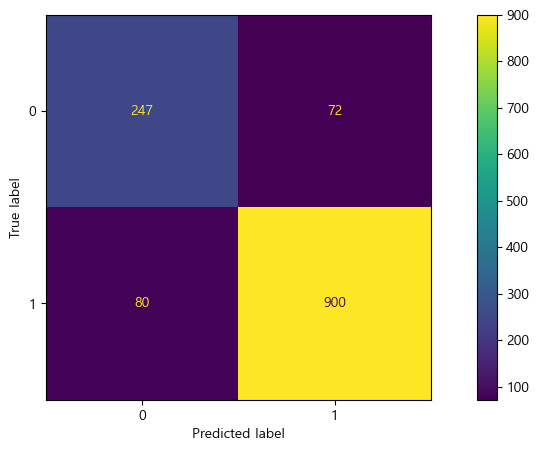

In [188]:
# 오차행렬표
cn_matrix = confusion_matrix(y_test, test_pred, labels=xgb.classes_)
display(cn_matrix)

# 오차행렬도
disp_test = ConfusionMatrixDisplay(confusion_matrix=cn_matrix, display_labels=xgb.classes_)
disp_test
disp_test.plot()
plt.show()